# 05 · Eventos: ¿el aire cambió más de lo esperable?

**Pregunta concreta.** En un día de paro sin colectivos, ¿la firma diésel (NOx/CO) fue **más baja de lo que se
esperaba para un día con ese clima**? ¿Y fue más baja que en los paros donde los colectivos funcionaron?

**Método, en tres pasos:**
1. **Modelo de un día normal.** Con los ~520 días hábiles normales que tienen datos del SMN ajustamos una regresión lineal (OLS) que
   explica el logaritmo de cada contaminante con el viento, la temperatura, la lluvia, la estación de monitoreo,
   el mes, el año y el día de la semana. No es un modelo de *machine learning*: es una forma ordenada de decir
   "un jueves de mayo con 8 km/h de viento, en La Boca, suele tener tanto NOx".
2. **Desvío del evento.** Para cada paro comparamos lo medido contra lo que el modelo esperaba para ese día.
   Como trabajamos en logaritmos, el desvío se lee en **porcentaje**.
3. **Prueba placebo.** ¿Un desvío así es raro? Lo comparamos con los desvíos de los días normales: si el paro
   queda en el percentil 1, solo el 1% de los días normales tuvo un desvío tan bajo.

Usamos el bloque 8-16 h y, como verificación, el promedio de 24 h.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dónde están los Parquet: export/ del repo (local, después de `uv run python run.py`)
# o la carpeta actual (Colab: subir los .parquet de export/ con el panel de archivos).
for BASE in [Path("../export"), Path("export"), Path(".")]:
    if (BASE / "gold_analitico.parquet").exists():
        break
else:
    raise FileNotFoundError("No encuentro gold_analitico.parquet: corré `uv run python run.py` o subilo a Colab")

d = pd.read_parquet(BASE / "gold_analitico.parquet")
d["fecha"] = pd.to_datetime(d["fecha"])
eventos = pd.read_parquet(BASE / "eventos.parquet")
eventos["fecha"] = pd.to_datetime(eventos["fecha"])

ESTACIONES = ["CENTENARIO", "CORDOBA", "LA BOCA"]
# Un color fijo por estación en todos los notebooks (paleta validada para daltonismo).
COLOR = {"CENTENARIO": "#2a78d6", "CORDOBA": "#eb6834", "LA BOCA": "#1baf7a"}
# Resaltado de eventos (solo en gráficos donde no se colorea por estación).
COLOR_EVENTO = {"sin_colectivos": "#6250d6", "control": "#eda100"}
GRIS, TINTA, TINTA_2 = "#b9b8b2", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "font.size": 10, "text.color": TINTA,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format
print(f"{len(d):,} filas (estación × día), {d.fecha.min():%d/%m/%Y} a {d.fecha.max():%d/%m/%Y}")

2,950 filas (estación × día), 01/01/2024 a 30/09/2026


In [2]:
import statsmodels.formula.api as smf

def fmt_p(p, repeticiones=5000):
    """Valor p de la prueba placebo: con 5.000 sorteos, 0 significa menor que 1/5.000."""
    return f"< {1 / repeticiones:.4f}" if p == 0 else f"{p:.4f}"

d["lluvia"] = d["hubo_lluvia"].astype(float)
# Con viento casi nulo el logaritmo explota: se fija un piso de 2 km/h.
d["log_viento"] = np.log(np.maximum(d["viento_kmh"], 2))
d["nox_co_24h"] = d["nox_24h_ppb"] / d["co_24h_ppm"].where(d["co_24h_ppm"] > 0)

METEO = ["viento_kmh", "temp_c", "lluvia"]
FORMULA = "~ log_viento + temp_c + lluvia + C(estacion) + C(mes) + C(anio) + C(dia_semana)"
VARIABLES = {"nox_co_816": "NOx/CO", "nox_816_ppb": "NOx", "co_816_ppm": "CO",
             "no2_816_ppb": "NO2", "pm10_816_ugm3": "PM10"}

normales = d[d.es_dia_normal & d.grupo_evento.isna()].dropna(subset=METEO)
ev = d[d.grupo_evento.notna()].dropna(subset=METEO)
print(f"Días normales con meteorología: {normales.fecha.nunique()} ({len(normales)} estación-día)")
print(f"Eventos: {ev.fecha.nunique()} días ({len(ev)} estación-día)")

Días normales con meteorología: 517 (1539 estación-día)
Eventos: 6 días (18 estación-día)


## 1. El modelo de un día normal

Para estimar qué tan bien predice el modelo usamos **validación cruzada** (10 partes): cada día normal se
predice con un modelo que no lo vio. Así sus desvíos son comparables con los de los paros, que tampoco
participan del ajuste.

In [3]:
def ajustar(col, base=normales, eventos=ev, partes=10, semilla=1):
    """Ajusta el modelo, calcula desvíos fuera de muestra de los días normales y desvíos de los eventos."""
    n = base[base[col] > 0].copy()
    n["y"] = np.log(n[col])
    modelo = smf.ols("y " + FORMULA, n).fit()
    grupo = np.random.default_rng(semilla).permutation(len(n)) % partes
    n["desvio"] = np.nan
    for k in range(partes):
        m_k = smf.ols("y " + FORMULA, n[grupo != k]).fit()
        prueba = n.index[grupo == k]
        n.loc[prueba, "desvio"] = n.loc[prueba, "y"] - m_k.predict(n.loc[prueba])
    e = eventos[eventos[col] > 0].copy()
    e["esperado"] = np.exp(modelo.predict(e))
    e["desvio"] = np.log(e[col]) - np.log(e["esperado"])
    # Percentil placebo: qué % de los días normales de esa estación tuvo un desvío menor.
    e["percentil"] = [(n.loc[n.estacion == s, "desvio"] < r).mean() * 100 for s, r in zip(e.estacion, e.desvio)]
    return modelo, n, e

modelos, normales_res, eventos_res = {}, {}, {}
resumen = []
for col, nombre in VARIABLES.items():
    m, n, e = ajustar(col)
    modelos[nombre], normales_res[nombre], eventos_res[nombre] = m, n, e
    resumen.append({"variable": nombre, "días-estación": int(m.nobs), "R²": m.rsquared,
                    "R² validación cruzada": 1 - n.desvio.var() / n.y.var(),
                    "viento ×2 (%)": (2 ** m.params["log_viento"] - 1) * 100,
                    "+1 °C (%)": (np.exp(m.params["temp_c"]) - 1) * 100,
                    "lluvia (%)": (np.exp(m.params["lluvia"]) - 1) * 100})
pd.DataFrame(resumen).set_index("variable").round(2)

,días-estación,R²,R² validación cruzada,viento ×2 (%),+1 °C (%),lluvia (%)
variable,,,,,,
NOx/CO,1203,0.50,0.48,-9.77,-1.42,-1.70
NOx,1242,0.46,0.44,-29.72,-0.07,4.48
CO,1409,0.47,0.45,-23.19,1.38,5.48
NO2,1242,0.57,0.55,-23.27,1.00,5.19
PM10,1367,0.19,0.16,-16.07,0.91,-1.17


**Cómo se lee.** "viento ×2" es cuánto cambia el contaminante si el viento se duplica, con todo lo demás igual.
- El modelo explica cerca de la mitad de la variación diaria de NOx, NO2, CO y NOx/CO, y poco del PM10
  (que depende de fuentes regionales). El R² de validación cruzada es parecido al del ajuste: no hay sobreajuste.
- Duplicar el viento baja mucho el NOx y bastante menos el NOx/CO: el cociente es más robusto a la dilución,
  como ya se vio en el notebook 04.

## 2. Cada evento contra su día esperado

La franja gris es el rango donde cae el 90% de los días normales (percentiles 5 a 95). Un punto a la izquierda
de la franja es un desvío que solo tiene el 5% de los días normales.

In [4]:
filas = []
for nombre, e in eventos_res.items():
    for _, r in e.iterrows():
        filas.append({"fecha": r.fecha, "evento": r.evento, "grupo": r.grupo_evento, "estacion": r.estacion,
                      "variable": nombre, "observado": r[[k for k, v in VARIABLES.items() if v == nombre][0]],
                      "esperado": r.esperado, "desvio_pct": (np.exp(r.desvio) - 1) * 100,
                      "percentil_placebo": r.percentil, "viento_kmh": r.viento_kmh, "lluvia_mm": r.precipitacion_mm})
resultados = pd.DataFrame(filas)
tabla = resultados.pivot_table(index=["grupo", "fecha", "estacion"], columns="variable",
                               values=["desvio_pct", "percentil_placebo"])
tabla = tabla.reindex(columns=["NOx/CO", "NOx", "CO"], level=1).sort_index(ascending=[False, True, True])
tabla.round(0)

desvio_pct                \
variable                                 NOx/CO    NOx     CO   
grupo          fecha      estacion                              
sin_colectivos 2024-04-11 CENTENARIO        NaN    NaN -20.00   
                          CORDOBA           NaN  25.00    NaN   
                          LA BOCA        -61.00 -27.00  98.00   
               2024-05-09 CENTENARIO        NaN    NaN -25.00   
                          CORDOBA           NaN -15.00    NaN   
                          LA BOCA        -60.00 -48.00  38.00   
               2025-05-06 CENTENARIO      15.00 -21.00 -27.00   
                          CORDOBA        -40.00 -24.00  22.00   
                          LA BOCA          2.00  -5.00 -10.00   
               2026-02-19 CENTENARIO     -57.00 -62.00  -6.00   
                          CORDOBA        -25.00  66.00 110.00   
                          LA BOCA        -68.00 -74.00 -22.00   
control        2024-10-30 CENTENARIO        NaN    NaN -29.00   
                          CORDOBA         20.00 -12.00 -21.00   
                          LA BOCA        -22.00 -17.00  17.00   
               2025-04-10 CENTENARIO     -34.00 -48.00 -17.00   
                          CORDOBA        -34.00 -23.00  11.00   
                          LA BOCA         45.00   4.00 -32.00   

                                     percentil_placebo              
variable                                        NOx/CO   NOx    CO  
grupo          fecha      estacion                                  
sin_colectivos 2024-04-11 CENTENARIO               NaN   NaN 22.00  
                          CORDOBA                  NaN 68.00   NaN  
                          LA BOCA                 1.00 18.00 98.00  
               2024-05-09 CENTENARIO               NaN   NaN 16.00  
                          CORDOBA                  NaN 32.00   NaN  
                          LA BOCA                 1.00  8.00 82.00  
               2025-05-06 CENTENARIO             65.00 26.00 15.00  
                          CORDOBA                 5.00 25.00 67.00  
                          LA BOCA                48.00 35.00 39.00  
               2026-02-19 CENTENARIO              1.00  0.00 46.00  
                          CORDOBA                13.00 89.00 99.00  
                          LA BOCA                 1.00  0.00 23.00  
control        2024-10-30 CENTENARIO               NaN   NaN 13.00  
                          CORDOBA                75.00 34.00 24.00  
                          LA BOCA                23.00 25.00 66.00  
               2025-04-10 CENTENARIO             10.00  0.00 27.00  
                          CORDOBA                 8.00 27.00 55.00  
                          LA BOCA                84.00 43.00 13.00

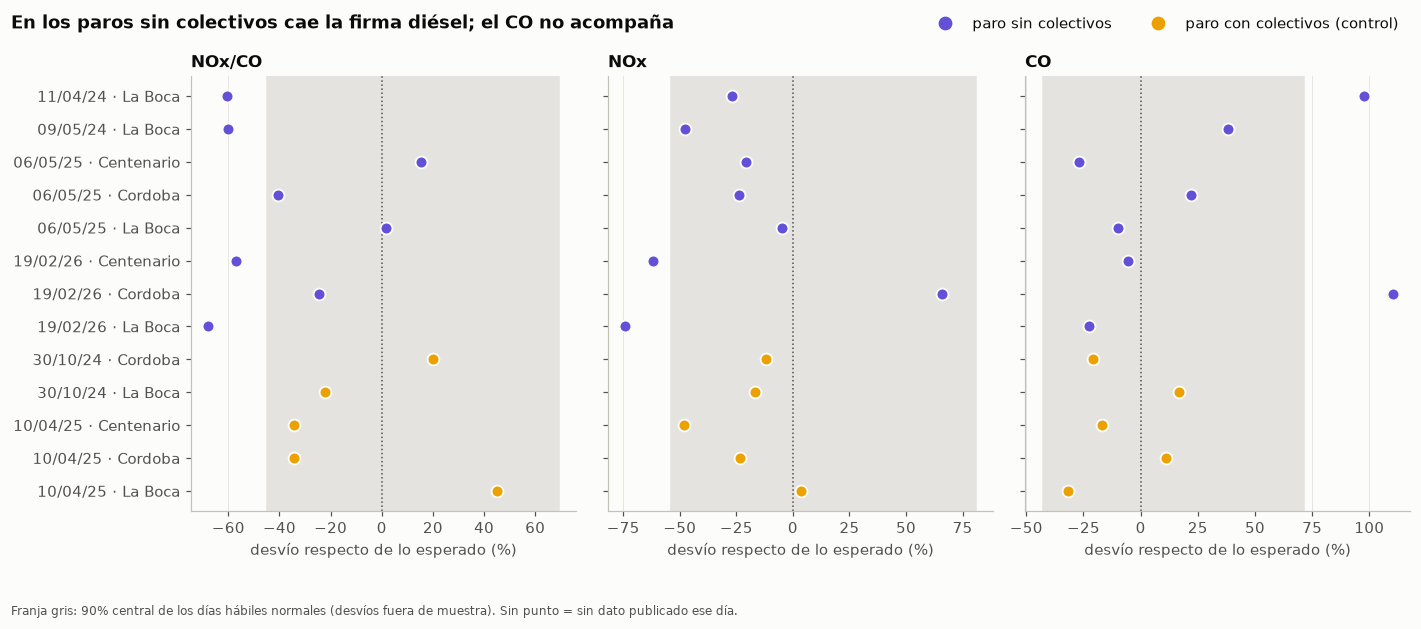

In [5]:
filas_graf = (resultados[resultados.variable == "NOx/CO"]
              .sort_values(["grupo", "fecha", "estacion"], ascending=[False, True, True]))
claves = list(zip(filas_graf.fecha, filas_graf.estacion))
fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), sharey=True)
for ax, nombre in zip(axes, ["NOx/CO", "NOx", "CO"]):
    n = normales_res[nombre]
    lo, hi = (np.exp(n.desvio.quantile([0.05, 0.95])) - 1) * 100
    ax.axvspan(lo, hi, color="#e4e3df", zorder=0)
    ax.axvline(0, color=TINTA_2, lw=1, ls=":")
    sub = resultados[resultados.variable == nombre].set_index(["fecha", "estacion"])
    for i, k in enumerate(claves[::-1]):
        if k in sub.index:
            r = sub.loc[k]
            ax.scatter(r.desvio_pct, i, s=60, color=COLOR_EVENTO[r.grupo], edgecolor="#fcfcfb", linewidth=1.2, zorder=3)
    ax.set_title(nombre)
    ax.set_xlabel("desvío respecto de lo esperado (%)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(claves)), [f"{f:%d/%m/%y} · {e.title()}" for f, e in claves[::-1]])
from matplotlib.lines import Line2D
marcas = [Line2D([], [], marker="o", ls="", markersize=8, color=COLOR_EVENTO[g], label=et)
          for g, et in [("sin_colectivos", "paro sin colectivos"), ("control", "paro con colectivos (control)")]]
fig.suptitle("En los paros sin colectivos cae la firma diésel; el CO no acompaña", x=0.01, ha="left",
             fontweight="bold")
fig.text(0.01, -0.07, "Franja gris: 90% central de los días hábiles normales (desvíos fuera de muestra). "
         "Sin punto = sin dato publicado ese día.", fontsize=8, color=TINTA_2)
plt.tight_layout()
fig.legend(handles=marcas, loc="upper right", bbox_to_anchor=(0.99, 1.0), ncol=2)

## 3. Prueba placebo del grupo

Un evento aislado puede caer en el extremo por azar. La pregunta fuerte es: **¿cuán probable es que 4 días
normales elegidos al azar tengan, en promedio, un desvío tan bajo como los 4 paros?**

Se sortean días normales completos (con todas las estaciones que tenían dato en cada paro, para respetar que
las estaciones de un mismo día se parecen) y se repite 5.000 veces. El **valor p** es la proporción de sorteos
con un promedio igual o más bajo que el de los paros.

In [6]:
def placebo_grupo(nombre, grupo, eventos=None, repeticiones=5000, semilla=0):
    e = eventos_res[nombre] if eventos is None else eventos
    e = e[e.grupo_evento == grupo]
    observado = e.desvio.mean()
    tabla_dias = normales_res[nombre].pivot_table(index="fecha", columns="estacion", values="desvio")
    rng = np.random.default_rng(semilla)
    candidatos = {f: tabla_dias[list(sub.estacion)].dropna().values for f, sub in e.groupby("fecha")}
    sims = np.empty(repeticiones)
    for i in range(repeticiones):
        vals = [c[rng.integers(len(c))] for c in candidatos.values()]
        sims[i] = np.concatenate(vals).mean()
    return observado, sims, (sims <= observado).mean(), len(e), e.fecha.nunique()

grupos = []
sims_guardadas = {}
for nombre in VARIABLES.values():
    for grupo in ["sin_colectivos", "control"]:
        obs, sims, p, n_obs, n_dias = placebo_grupo(nombre, grupo)
        sims_guardadas[(nombre, grupo)] = (obs, sims)
        grupos.append({"variable": nombre, "grupo": grupo, "días": n_dias, "estación-día": n_obs,
                       "desvío medio (%)": (np.exp(obs) - 1) * 100, "valor p": p})
grupos = pd.DataFrame(grupos)
vista = grupos.assign(**{"valor p": grupos["valor p"].map(fmt_p), "desvío medio (%)": grupos["desvío medio (%)"].round(0)})
vista.pivot(index="variable", columns="grupo", values=["desvío medio (%)", "valor p"]).reindex(VARIABLES.values())

desvío medio (%)                valor p               
grupo             control sin_colectivos control sin_colectivos
variable                                                       
NOx/CO             -10.00         -43.00  0.2054       < 0.0002
NOx                -21.00         -28.00  0.0656         0.0016
CO                 -14.00           7.00  0.1890         0.7468
NO2                -14.00         -23.00  0.1510         0.0068
PM10               -23.00         -15.00  0.1268         0.1694

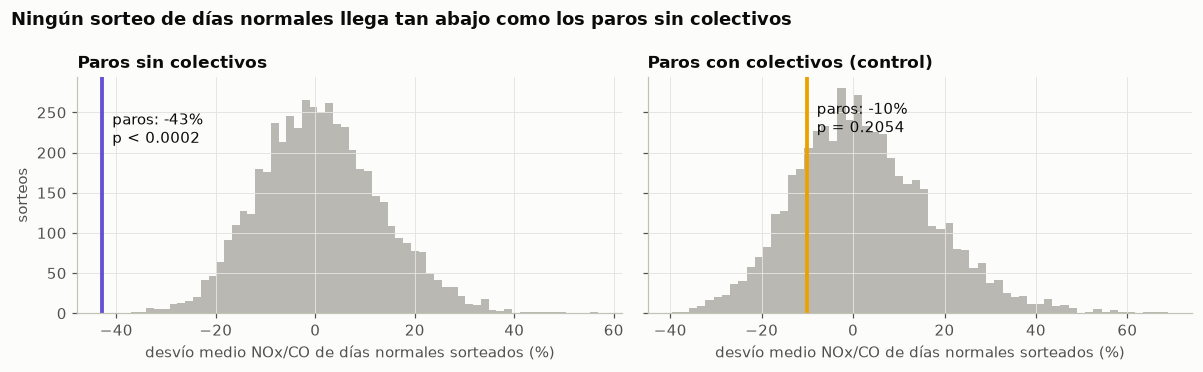

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, grupo in zip(axes, ["sin_colectivos", "control"]):
    obs, sims = sims_guardadas[("NOx/CO", grupo)]
    ax.hist((np.exp(sims) - 1) * 100, bins=60, color=GRIS)
    ax.axvline((np.exp(obs) - 1) * 100, color=COLOR_EVENTO[grupo], lw=2.5)
    p = (sims <= obs).mean()
    ax.text((np.exp(obs) - 1) * 100, ax.get_ylim()[1] * 0.9, f"  paros: {(np.exp(obs) - 1) * 100:.0f}%\n  p {fmt_p(p) if p == 0 else '= ' + fmt_p(p)}",
            color=TINTA, va="top")
    ax.set_title({"sin_colectivos": "Paros sin colectivos", "control": "Paros con colectivos (control)"}[grupo])
    ax.set_xlabel("desvío medio NOx/CO de días normales sorteados (%)")
axes[0].set_ylabel("sorteos")
fig.suptitle("Ningún sorteo de días normales llega tan abajo como los paros sin colectivos", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()

## 4. ¿El resultado depende de un solo paro o de la ventana horaria?

- **Sacando un paro por vez:** si el resultado dependiera de un único día, al sacarlo desaparecería.
- **Promedio de 24 h** en lugar del bloque 8-16 h: incluye la noche, cuando casi no circulan colectivos, así
  que podría diluir el efecto. Si el resultado fuera un artefacto de la ventana elegida, cambiaría.

In [8]:
filas = []
e_all = eventos_res["NOx/CO"]
for fecha in sorted(e_all.loc[e_all.grupo_evento == "sin_colectivos", "fecha"].unique()):
    e_sin = e_all[e_all.fecha != fecha]
    obs, _, p, n_obs, n_dias = placebo_grupo("NOx/CO", "sin_colectivos", eventos=e_sin)
    filas.append({"sin el paro del": f"{pd.Timestamp(fecha):%d/%m/%Y}", "días": n_dias,
                  "desvío medio NOx/CO (%)": round((np.exp(obs) - 1) * 100), "valor p": fmt_p(p)})
pd.DataFrame(filas)

,sin el paro del,días,desvío medio NOx/CO (%),valor p
0,11/04/2024,3,-40,0.0002
1,09/05/2024,3,-40,0.0002
2,06/05/2025,3,-56,< 0.0002
3,19/02/2026,3,-36,0.0034


In [9]:
_, n24, e24 = ajustar("nox_co_24h")
normales_res["NOx/CO 24 h"], eventos_res["NOx/CO 24 h"] = n24, e24
filas = []
for grupo in ["sin_colectivos", "control"]:
    for nombre in ["NOx/CO", "NOx/CO 24 h"]:
        obs, _, p, n_obs, n_dias = placebo_grupo(nombre, grupo)
        filas.append({"grupo": grupo, "ventana": "8-16 h" if nombre == "NOx/CO" else "24 h",
                      "desvío medio (%)": round((np.exp(obs) - 1) * 100), "valor p": fmt_p(p)})
pd.DataFrame(filas)

,grupo,ventana,desvío medio (%),valor p
0,sin_colectivos,8-16 h,-43,< 0.0002
1,sin_colectivos,24 h,-44,< 0.0002
2,control,8-16 h,-10,0.2054
3,control,24 h,-12,0.1596


## 5. Resultados para el dashboard

Se guardan dos tablas en `export/` para Power BI:
- `resultados_evento.parquet`: una fila por evento, estación y variable (observado, esperado, desvío %,
  percentil placebo).
- `resultados_grupo.parquet`: desvío medio y valor p por grupo y variable.

In [10]:
resultados.to_parquet(BASE / "resultados_evento.parquet", index=False)
(grupos.rename(columns={"días": "dias", "estación-día": "estacion_dia", "desvío medio (%)": "desvio_medio_pct",
                        "valor p": "valor_p"})
       .to_parquet(BASE / "resultados_grupo.parquet", index=False))
print(f"Guardado en {BASE}: resultados_evento ({len(resultados)} filas), resultados_grupo ({len(grupos)} filas)")

Guardado en ../export: resultados_evento (74 filas), resultados_grupo (10 filas)


**Lectura de la sección 4.** Sacando cualquiera de los cuatro paros, el desvío medio sigue entre −36% y −56% y el
valor p queda por debajo de 0,004: **el resultado no depende de un único día**. Con el promedio de 24 h el
resultado es prácticamente el mismo (−44%), así que tampoco depende de haber elegido el bloque 8-16 h.

## Conclusiones

**Respuesta a la pregunta.** En los días de paro sin colectivos, la firma diésel del aire porteño (NOx/CO)
fue en promedio **un 43% más baja de lo esperable** para un día con esa meteorología. En 5.000 sorteos de días
normales ninguno llegó tan abajo. En los paros donde los colectivos funcionaron, el desvío fue de −10%, dentro
de lo habitual (p ≈ 0,2). **Los resultados son consistentes con la hipótesis.**

**Qué hay detrás del cociente:**
- El **NOx bajó** un 28% respecto de lo esperado (p ≈ 0,002) y el **NO2**, un 23% (p ≈ 0,01).
- El **CO no bajó** (+7%, dentro de lo normal). Es consistente con que quienes no tienen colectivo usen auto,
  taxi o remís: la nafta se mantiene o sube mientras el diésel desaparece. En La Boca, en los paros de 2024,
  el CO subió fuerte (+98% y +38%): ahí buena parte de la caída del cociente viene de más CO, no solo de
  menos NOx.
- El **PM10 no muestra un efecto distinguible** (p ≈ 0,17): depende de fuentes regionales, no solo del tránsito.
- En los **controles** el NOx también bajó algo (−21%, p ≈ 0,07), pero el CO bajó a la par y el cociente quedó
  normal: menos tránsito en general, no menos diésel en particular.

**Evento por evento:**
- **19/02/2026** (paro general): el más claro, percentil 1 en Centenario y La Boca. Córdoba ese día tuvo NOx
  y CO muy por encima de lo esperado: algo local (más autos en la avenida, una fuente puntual) que conviene
  revisar.
- **11/04/2024 y 09/05/2024:** percentil 1 en La Boca, la única estación con NOx y CO publicados esos días.
- **06/05/2025** (paro UTA con 11 mm de lluvia): efecto débil salvo en Córdoba. La lluvia lava el aire y el
  modelo la captura solo con una variable sí/no.

**Limitaciones (para decirlas en la exposición):**
1. **Pocos eventos:** 4 paros sin colectivos y 2 de control; 8 combinaciones estación-día con NOx/CO.
   Por eso hablamos de evidencia consistente, no de demostración.
2. **Colectivos o camiones:** dos de los cuatro paros fueron generales; si los camiones también pararon, parte
   de la caída del NOx es de ellos. Los dos paros solo de UTA dan resultados distintos (fuerte en 2024, débil
   con lluvia en 2025), así que con estos datos no se puede separar del todo.
3. **SUBE mide pasajeros**, no colectivos en la calle ni kilómetros recorridos dentro de la Ciudad.
4. **Meteorología diaria:** el SMN da promedios de 24 h, no la ventana 8-16 h, y la lluvia es diaria.
5. **Datos públicos redondeados** (NOx en ppb enteros, CO con un decimal) y huecos de la fuente (2024 solo
   La Boca).
6. **Es un estudio observacional:** el modelo descuenta clima y calendario, pero no todo lo que cambia un día
   de paro (manifestaciones, cortes, menos actividad general).